# Spike inference comparison: suite2p (OASIS) vs OMSI

One recording, `260903_SAM044_distance-temporal`, analysed three ways. The suite2p ROIs, `iscell`,
frame times and stimulus file are byte-identical across all three session folders, so `cell_id`
(the raw suite2p row index) means the same thing everywhere and every difference below comes from
`spks.npy` alone.

| session folder | what `spks.npy` holds |
| --- | --- |
| `260903_SAM044_distance-temporal` | suite2p OASIS deconvolution, continuous amplitude |
| `260903_SAM044_distance-temporal_newspikes` | OMSI inferred spike counts per frame |
| `260903_SAM044_distance-temporal_newspikes_prob` | OMSI posterior spike trace, expected spikes per frame, can exceed 1 |

**Regenerating the OMSI folders.** OMSI needs `ray`, which this kernel does not have, so it runs
from the `spikeinf` environment:

```
"C:\Users\acostamendoza\AppData\Local\anaconda3\envs\spikeinf\python.exe" ^
    radial-analysis\run-scripts\run_omsi_spikes.py ^
    --session 260903_SAM044_distance-temporal --overwrite
```

**One thing to watch.** OMSI leaves some cells with zero inferred spikes. Those rows are all zero,
which `RadialDevice` z-scoring turns into NaN. The diagnostic cell below builds `valid_ids` and
every comparison afterwards is restricted to it.

In [1]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from src.data.RadialDevice import RadialDevice
from src.analysis.CellAnalysis import CellAnalyzer, SessionAnalyzer
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SingleSessionVisualizer
from src.workflows import analyze_session
from src.utils import create_new_result_dir

%load_ext autoreload
%autoreload 2

base_data_dir = r'D:\data-distance-coding-project\processed-data'
mouse_name  = 'SAM044'
record_date = '260903'

# The three arms of the comparison: key -> experiment_name of the session folder.
METHODS = {
    'suite2p':   'distance-temporal',
    'omsi':      'distance-temporal_newspikes',
    'omsi_prob': 'distance-temporal_newspikes_prob',
}
LABELS = {'suite2p': 'suite2p (OASIS)', 'omsi': 'OMSI counts', 'omsi_prob': 'OMSI prob'}
COLORS = {'suite2p': '#4c72b0', 'omsi': '#dd8452', 'omsi_prob': '#55a868'}


def plane_dir(key):
    """suite2p/plane0 directory for one arm."""
    return os.path.join(base_data_dir, f'{record_date}_{mouse_name}_{METHODS[key]}',
                        'suite2p', 'plane0')


def cond_field(df, field, condition='binocular'):
    """Pull one field out of a per-condition dict column, indexed by cell_id.

    The monocular/binocular columns hold dicts with keys RF, reliable, reliable_corr,
    bootstrap_pvalue, anova_pvalue, consistency, DTI, distance.
    """
    values = [d.get(field, np.nan) if isinstance(d, dict) else np.nan
              for d in df[condition]]
    return pd.Series(values, index=df['cell_id'].values, name=field)

## Load the three sessions

In [2]:
# The suite2p arm has a cached _dataframe.pkl and loads instantly; the two OMSI arms
# compute from scratch the first time. Pass force_recompute=True if the analysis code
# changed since a cache was written.
dfs, devices = {}, {}

for key, experiment in METHODS.items():
    dfs[key], devices[key] = analyze_session(
        mouse_name=mouse_name,
        record_date=record_date,
        experiment_name=experiment,
        show_plots=False,
    )
    dev = devices[key]
    print(f'{key:10s} {len(dfs[key]):4d} cells   response {dev.response.shape}   '
          f'on_length {dev.on_length}')

Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260903_SAM044_distance-temporal\260903_SAM044_distance-temporal_dataframe.pkl
suite2p     953 cells   response (953, 14432)   on_length 60
Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260903_SAM044_distance-temporal_newspikes\260903_SAM044_distance-temporal_newspikes_dataframe.pkl
omsi        953 cells   response (953, 14432)   on_length 60
Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260903_SAM044_distance-temporal_newspikes_prob\260903_SAM044_distance-temporal_newspikes_prob_dataframe.pkl
omsi_prob   953 cells   response (953, 14432)   on_length 60


## Diagnostic: matched geometry and the zero-spike cells

In [3]:
# All three folders share frames_time.npy and the stimulus .mat, so the trial geometry
# must be identical. If this trips, the folders are out of sync and nothing below is
# comparable.
on_lengths = {k: d.on_length for k, d in devices.items()}
assert len(set(on_lengths.values())) == 1, f'on_length differs across methods: {on_lengths}'

cell_id_sets = {k: set(df['cell_id'].values) for k, df in dfs.items()}
assert cell_id_sets['suite2p'] == cell_id_sets['omsi'] == cell_id_sets['omsi_prob'], \
    'cell_id sets differ -- iscell.npy is not the same across folders'

frames_time = devices['suite2p'].frames_time
fs = 1000.0 / np.median(np.diff(frames_time))
print(f'on_length {on_lengths["suite2p"]}   frame rate {fs:.3f} Hz   '
      f'{len(cell_id_sets["suite2p"])} cells shared')

# A cell with no inferred spikes has an all-zero spks row, so z-scoring divides by zero.
finite_ids = {}
for key, dev in devices.items():
    ok = np.isfinite(dev.response).all(axis=1)
    finite_ids[key] = set(np.asarray(dev.suite2p_id)[ok])
    print(f'{key:10s} {ok.sum():4d} / {len(ok)} cells with a finite response')

zero_spike_ids = np.load(os.path.join(plane_dir('omsi'), 'omsi_zero_spike_cell_ids.npy'))
spike_times = np.load(os.path.join(plane_dir('omsi'), 'omsi_spike_times.npy'),
                      allow_pickle=True)
n_spikes = np.array([len(s) for s in spike_times])

valid_ids = set.intersection(*finite_ids.values())
print(f'\nOMSI zero-spike cells: {len(zero_spike_ids)}')
print(f'valid_ids (finite under all three methods): {len(valid_ids)}')
print(f'OMSI spikes per cell: median {np.median(n_spikes):.0f}, '
      f'mean rate {np.mean(n_spikes) / (len(frames_time) / fs):.3f} Hz')

on_length 60   frame rate 10.022 Hz   953 cells shared
suite2p     953 / 953 cells with a finite response
omsi        953 / 953 cells with a finite response
omsi_prob   953 / 953 cells with a finite response

OMSI zero-spike cells: 0
valid_ids (finite under all three methods): 953
OMSI spikes per cell: median 158, mean rate 0.130 Hz


## Raw traces

Read straight from the three `spks.npy` files rather than from `device.response`, so the
pipeline's z-scoring and Gaussian smoothing do not hide the difference. Each trace is scaled to
its own peak inside the window, so timing and shape are comparable but amplitude is not.

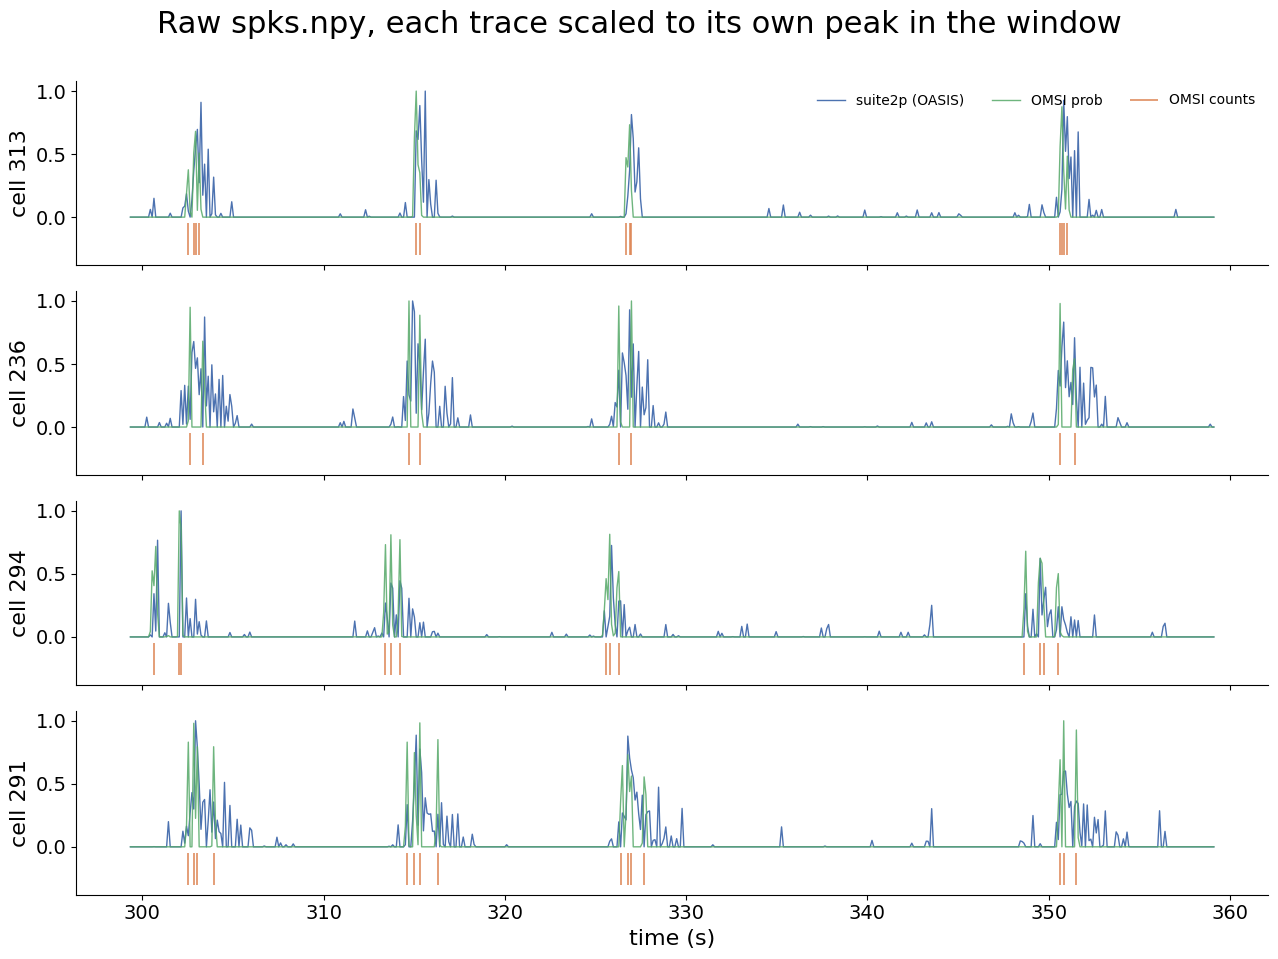

In [4]:
spks = {k: np.load(os.path.join(plane_dir(k), 'spks.npy'), mmap_mode='r') for k in METHODS}

# Show the cells suite2p likes best, so any disagreement is not just a noise floor.
ranked = cond_field(dfs['suite2p'], 'reliable_corr').loc[sorted(valid_ids)]
example_ids = list(ranked.sort_values(ascending=False).index[:4])

t0, t1 = 3000, 3600          # a 60 s window
t = np.arange(t0, t1) / fs

fig, axes = plt.subplots(len(example_ids), 1, figsize=(13, 2.4 * len(example_ids)),
                         sharex=True)
axes = np.atleast_1d(axes)

for ax, cell_id in zip(axes, example_ids):
    s2p = np.asarray(spks['suite2p'][cell_id, t0:t1], dtype=float)
    prb = np.asarray(spks['omsi_prob'][cell_id, t0:t1], dtype=float)
    cnt = np.asarray(spks['omsi'][cell_id, t0:t1], dtype=float)

    ax.plot(t, s2p / (s2p.max() or 1.0), color=COLORS['suite2p'], lw=1.0,
            label=LABELS['suite2p'])
    ax.plot(t, prb / (prb.max() or 1.0), color=COLORS['omsi_prob'], lw=1.0, alpha=0.85,
            label=LABELS['omsi_prob'])
    ax.vlines(t[cnt > 0], -0.30, -0.05, color=COLORS['omsi'], lw=1.1, label=LABELS['omsi'])

    ax.set_ylabel(f'cell {cell_id}')
    ax.set_ylim(-0.38, 1.08)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(loc='upper right', ncol=3, frameon=False, fontsize=10)
axes[-1].set_xlabel('time (s)')
fig.suptitle('Raw spks.npy, each trace scaled to its own peak in the window', y=1.0)
fig.tight_layout()

## How many cells each method calls reliable and modulated

In [5]:
viz = {k: SingleSessionVisualizer(dfs[k]) for k in METHODS}

rows = []
for key in METHODS:
    v = viz[key]
    row = {'method': LABELS[key],
           'cells': len(dfs[key]),
           'reliable': len(v.reliable_classes['reliable'])}
    for cls in ['monocular', 'binocular', 'both', 'none']:
        row[cls] = len(v.modulated_classes[cls])
    rows.append(row)

counts = pd.DataFrame(rows).set_index('method')
counts

,cells,reliable,monocular,binocular,both,none
method,,,,,,
suite2p (OASIS),953,684,104,134,29,417
OMSI counts,953,483,66,81,13,323
OMSI prob,953,511,76,90,10,335


In [ ]:
CLASSES = ['monocular', 'binocular', 'both', 'none']

rows = []
for key in METHODS:
    v = viz[key]
    n_reliable = len(v.reliable_classes['reliable'])
    n = {c: len(v.modulated_classes[c]) for c in CLASSES}
    # The four classes partition the reliable set, so 'modulated' is the complement of 'none'.
    assert sum(n.values()) == n_reliable, (key, n, n_reliable)
    n['modulated'] = n_reliable - n['none']

    row = {'method': LABELS[key], 'reliable': n_reliable}
    for c in ['modulated'] + CLASSES:
        row[f'{c} %'] = round(100.0 * n[c] / n_reliable, 1)
    rows.append(row)

pd.DataFrame(rows).set_index('method')

,reliable,modulated %,monocular %,binocular %,both %,none %
method,,,,,,
suite2p (OASIS),684,39.0,15.2,19.6,4.2,61.0
OMSI counts,483,33.1,13.7,16.8,2.7,66.9
OMSI prob,511,34.4,14.9,17.6,2.0,65.6


## Do the methods pick the same cells?

Set overlap on `cell_id`, restricted to `valid_ids`. This is the question the comparison exists to
answer: a method that finds more modulated cells is only interesting if they are the same cells.

In [6]:
def modulated_ids(key, cls):
    return set(viz[key].modulated_classes[cls]['cell_id'].values) & valid_ids


overlap_rows = []
for cls in ['binocular', 'monocular', 'both']:
    reference = modulated_ids('suite2p', cls)
    for key in ['omsi', 'omsi_prob']:
        other = modulated_ids(key, cls)
        union = reference | other
        overlap_rows.append({
            'class': cls,
            'vs': LABELS[key],
            'suite2p': len(reference),
            'other': len(other),
            'shared': len(reference & other),
            'suite2p only': len(reference - other),
            'other only': len(other - reference),
            'jaccard': round(len(reference & other) / len(union), 3) if union else np.nan,
        })

overlap = pd.DataFrame(overlap_rows).set_index(['class', 'vs'])
overlap

suite2p  other  shared  suite2p only  other only  \
class     vs                                                              
binocular OMSI counts      134     81      59            75          22   
          OMSI prob        134     90      67            67          23   
monocular OMSI counts      104     66      47            57          19   
          OMSI prob        104     76      55            49          21   
both      OMSI counts       29     13       7            22           6   
          OMSI prob         29     10       4            25           6   

                       jaccard  
class     vs                    
binocular OMSI counts    0.378  
          OMSI prob      0.427  
monocular OMSI counts    0.382  
          OMSI prob      0.440  
both      OMSI counts    0.200  
          OMSI prob      0.114

## Receptive field distributions

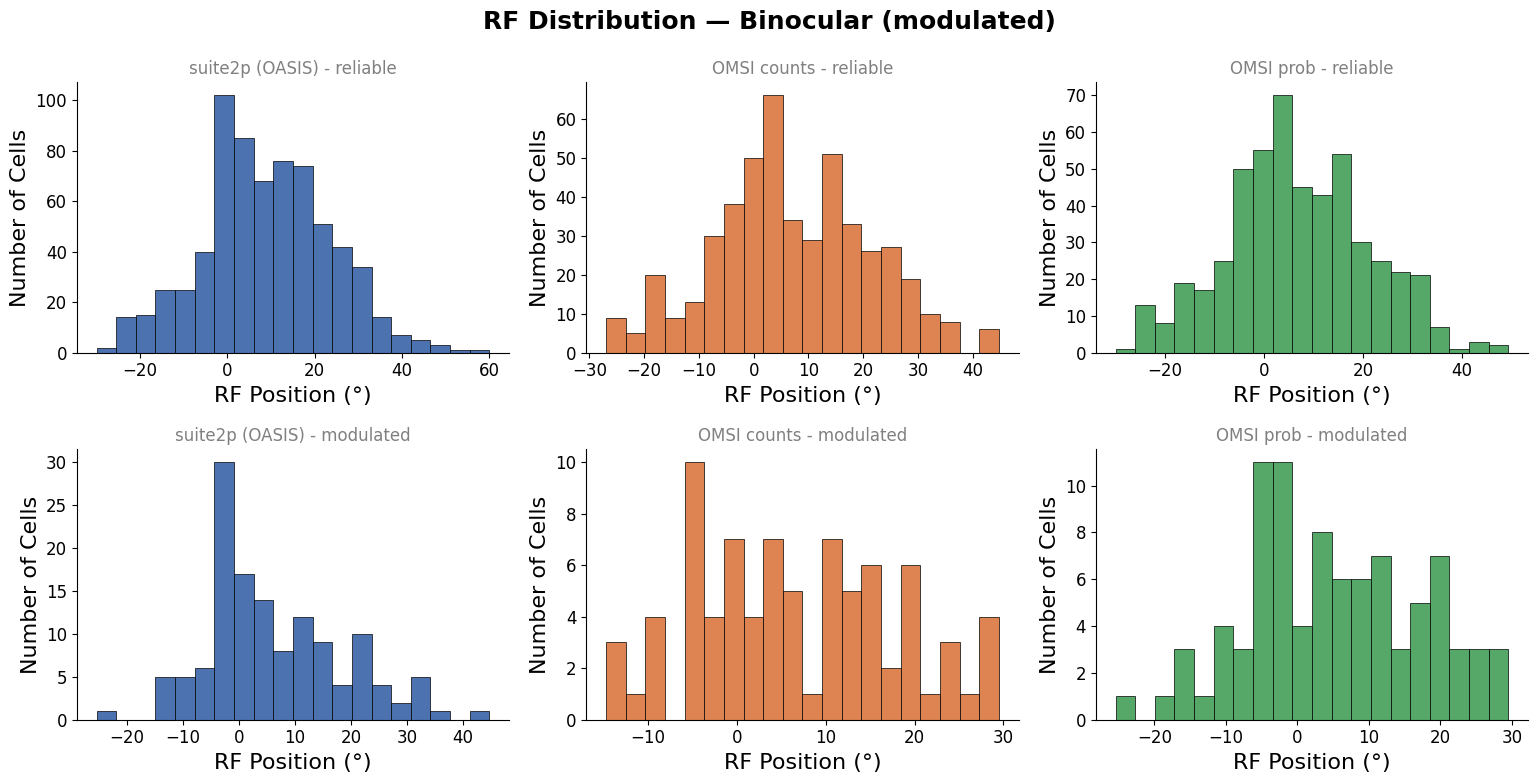

In [ ]:
fig, axes = plt.subplots(2, len(METHODS), figsize=(5.2 * len(METHODS), 8))
for j, key in enumerate(METHODS):
    for i, subset in enumerate(['reliable', 'modulated']):
        viz[key].plot_rf_histogram(condition='binocular', subset=subset,
                                   ax=axes[i, j], color=COLORS[key])
        axes[i, j].set_title(f'{LABELS[key]} - {subset}', fontsize=12)
fig.tight_layout()

C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\viz\SessionVisualizer.py:696: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


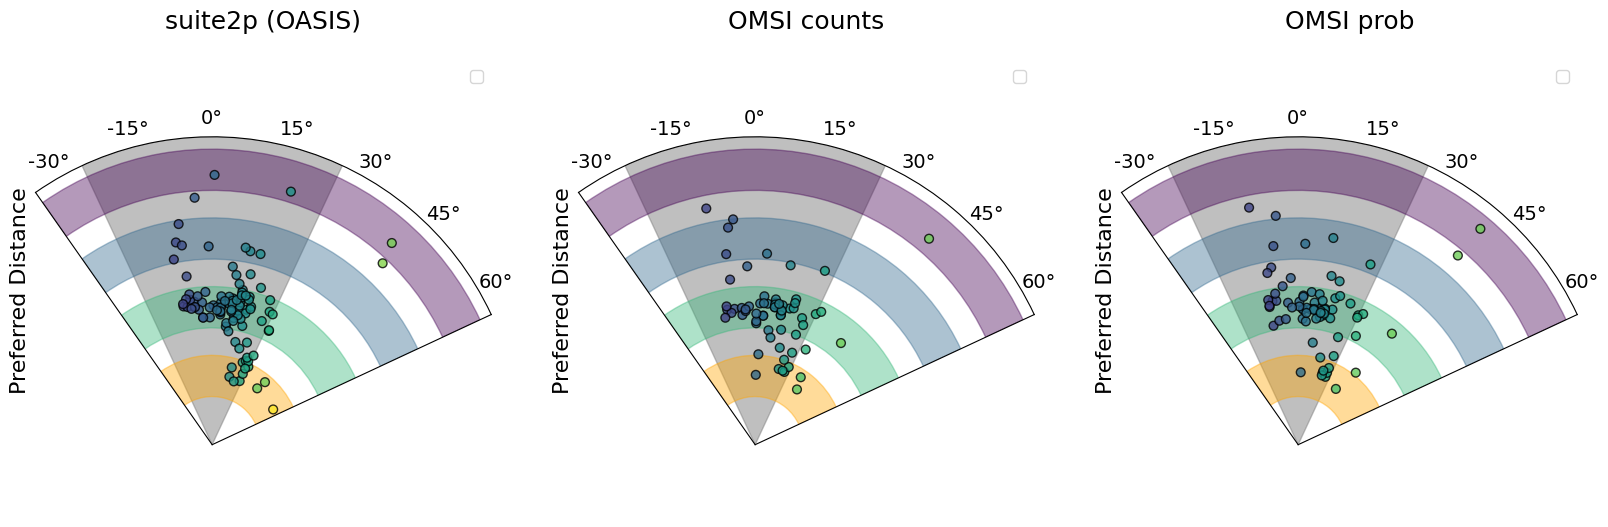

In [9]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(5.5 * len(METHODS), 5.5),
                         subplot_kw={'projection': 'polar'})
for ax, key in zip(np.atleast_1d(axes), METHODS):
    viz[key].plot_preferred_distance_polar(condition='monocular', ax=ax)
    ax.set_title(LABELS[key], pad=24)
fig.tight_layout()

## Per-cell statistics, matched by `cell_id`

The quantitative core. Each point is one cell, its suite2p value against its OMSI value, with the
identity line and a Spearman correlation. A method that merely rescales the response would sit on
the diagonal; a method that changes which cells look tuned would not.

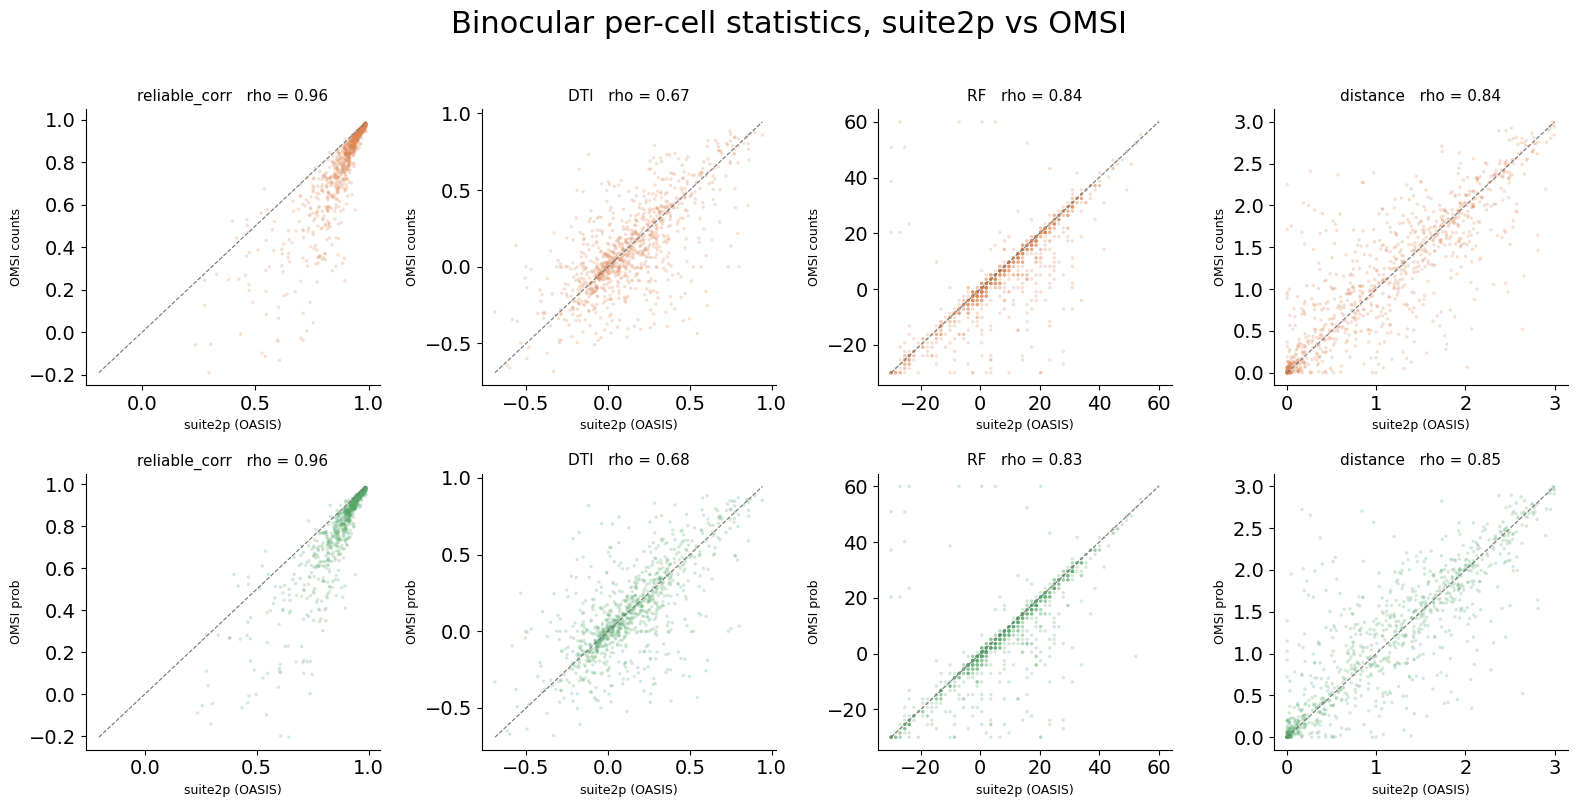

In [10]:
ids = np.array(sorted(valid_ids))
fields = ['reliable_corr', 'DTI', 'RF', 'distance']

fig, axes = plt.subplots(2, len(fields), figsize=(4.0 * len(fields), 8))
for j, field in enumerate(fields):
    reference = cond_field(dfs['suite2p'], field).loc[ids].astype(float).values
    for i, key in enumerate(['omsi', 'omsi_prob']):
        other = cond_field(dfs[key], field).loc[ids].astype(float).values
        ok = np.isfinite(reference) & np.isfinite(other)
        ax = axes[i, j]

        ax.scatter(reference[ok], other[ok], s=6, alpha=0.25, color=COLORS[key],
                   edgecolors='none')
        lo = min(reference[ok].min(), other[ok].min())
        hi = max(reference[ok].max(), other[ok].max())
        ax.plot([lo, hi], [lo, hi], color='0.45', lw=0.8, ls='--')

        rho, pval = spearmanr(reference[ok], other[ok])
        ax.set_title(f'{field}   rho = {rho:.2f}', fontsize=11)
        ax.set_xlabel(LABELS['suite2p'], fontsize=9)
        ax.set_ylabel(LABELS[key], fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Binocular per-cell statistics, suite2p vs OMSI', y=1.01)
fig.tight_layout()

## Decoding distance from the population

`build_decoder_data` and `_SingleSessionAgg` are carried over from
`analysis-comparing-sessions.ipynb`; they are notebook-local there, not importable. Two changes:
cell selection is restricted to `valid_ids`, and the top-cell ranking further down indexes the
cells actually in `X` rather than the full dataframe.

In [11]:
from src.decoding.Decoders import TrialDecoder, AveragedDecoder


def build_decoder_data(device, session_df, keep_ids=None):
    """Trial tensor for one session.

    Returns X (n_neurons, n_positions, n_trials), y_dist (n_trials,),
    distances (n_distances,), angle_axis (n_positions,), cell_ids (n_neurons,).
    """
    def _reliable(row):
        v = row['binocular']
        return isinstance(v, dict) and v.get('reliable', False)

    cell_ids = session_df[session_df.apply(_reliable, axis=1)]['cell_id'].values
    if keep_ids is not None:
        cell_ids = np.array([c for c in cell_ids if c in keep_ids])

    # Binocular trials (monocular == 0), excluding the control distance 4.
    mono_seq = np.array(device.monocular_sequence)
    dist_seq = np.array(device.distance_sequence)
    trial_mask = (mono_seq == 0) & (dist_seq != 4)
    trial_idx = np.where(trial_mask)[0]
    y_distance = dist_seq[trial_mask]

    traces = []
    for cell_id in cell_ids:
        cell_idx = np.where(device.suite2p_id == cell_id)[0][0]
        traces.append(np.stack(
            [device.get_on_trace(cell_idx, int(r)) for r in trial_idx], axis=0))

    X = np.stack(traces, axis=0).transpose(0, 2, 1)   # (n_neurons, n_positions, n_trials)
    angle_axis = np.linspace(float(device.start_angle), float(device.end_angle), X.shape[1])

    return X, y_distance, np.unique(y_distance), angle_axis, cell_ids


class _SingleSessionAgg:
    """Duck-types the SessionAggregator interface the decoders expect."""

    def __init__(self, X, y_distance, distances, angle_axis, df, cell_ids):
        self._X = X
        self._y = y_distance
        self._df = df
        self.cell_ids = cell_ids
        self.distances = distances
        self.angle_axis = angle_axis
        self.trial_info = {}

    @property
    def n_positions(self):
        return len(self.angle_axis)

    def _get_cell_indices(self, area=None, session=None):
        return list(range(self._X.shape[0]))

    def get_decoder_data(self, monocular=None, area=None, session=None, **kwargs):
        return self._X, self._y

    def get_split_decoder_data(self, monocular=None, area=None, session=None,
                               distances=None, test_fraction=0.5, random_state=None,
                               **kwargs):
        rng = np.random.RandomState(random_state)
        X, y = self._X, self._y
        dists = self.distances if distances is None else np.array(distances)

        train_avgs, test_avgs = [], []
        for d in dists:
            idx = np.where(y == d)[0]
            rng.shuffle(idx)
            split = max(1, int(len(idx) * (1 - test_fraction)))
            train_avgs.append(X[:, :, idx[:split]].mean(axis=2))
            test_avgs.append(X[:, :, idx[split:]].mean(axis=2))

        return np.stack(train_avgs, axis=2), np.stack(test_avgs, axis=2), dists


aggs = {}
for key in METHODS:
    X, y, dists, angles, cids = build_decoder_data(devices[key], dfs[key],
                                                   keep_ids=valid_ids)
    aggs[key] = _SingleSessionAgg(X, y, dists, angles, dfs[key], cids)
    print(f'{key:10s} {X.shape[0]:4d} cells, {X.shape[2]} trials, {X.shape[1]} positions')

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_40056\2327663012.py:32: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  angle_axis = np.linspace(float(device.start_angle), float(device.end_angle), X.shape[1])


suite2p     868 cells, 48 trials, 60 positions
omsi        744 cells, 48 trials, 60 positions
omsi_prob   751 cells, 48 trials, 60 positions


In [12]:
def plot_distance_compare(results, title=''):
    """Distance decoding accuracy vs stimulus angle, one line per method.

    The built-in plot_distance_results is hardcoded to exactly two result dicts and two
    colours, so draw all three here from angle_axis and the per-position accuracy.
    """
    fig, ax = plt.subplots(figsize=(10, 4.2))

    for key, res in results.items():
        angle_axis = res['angle_axis']
        if 'dist_acc_by_pos_all' in res:
            acc_all = res['dist_acc_by_pos_all'] * 100
            acc_mean = acc_all.mean(axis=0)
            acc_sem = acc_all.std(axis=0) / np.sqrt(len(acc_all))
        else:
            pred, true = res['pred_dist'], res['true_dist']
            if pred.ndim == 2 and true.ndim == 1 and pred.shape[0] == len(true):
                correct = (pred == true[:, np.newaxis]).astype(float) * 100
                acc_mean = correct.mean(axis=0)
                acc_sem = correct.std(axis=0) / np.sqrt(len(true))
            else:
                acc_per_rep = (pred == true[np.newaxis]).mean(axis=1) * 100
                acc_mean = acc_per_rep.mean(axis=0)
                acc_sem = acc_per_rep.std(axis=0) / np.sqrt(len(acc_per_rep))

        ax.plot(angle_axis, acc_mean, color=COLORS[key], lw=1.8, label=LABELS[key])
        ax.fill_between(angle_axis, acc_mean - acc_sem, acc_mean + acc_sem,
                        color=COLORS[key], alpha=0.2)

    chance = 100 / len(next(iter(results.values()))['distances'])
    ax.axhline(chance, color='0.4', ls=':', lw=1.0)
    ax.text(ax.get_xlim()[0], chance + 1, 'chance', color='0.4', fontsize=9)

    ax.set_xlabel('stimulus angle (deg)')
    ax.set_ylabel('distance decoding accuracy (%)')
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()

    return fig

Repeat 20/20
  Angle MAE:    1.69°
  Dist Acc:     33.7%
Repeat 20/20
  Angle MAE:    1.69°
  Dist Acc:     33.8%
Repeat 20/20
  Angle MAE:    1.55°
  Dist Acc:     31.6%


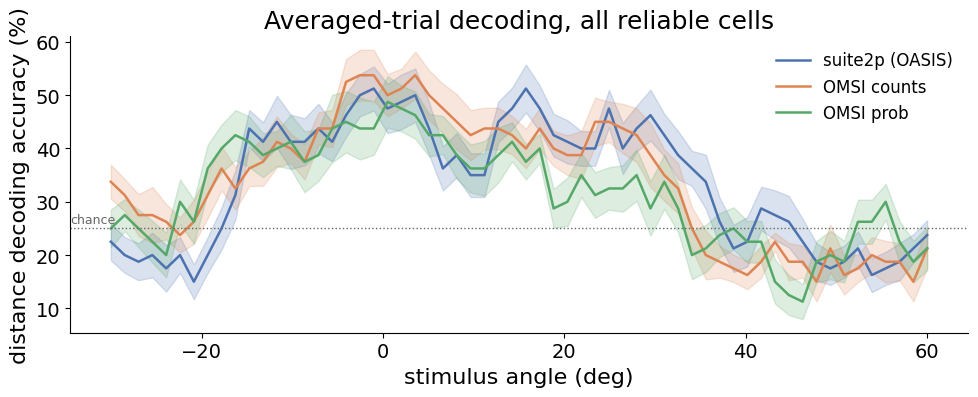

In [13]:
AvgDec = AveragedDecoder()
averaged = {key: AvgDec.cross_validate(aggs[key], monocular=0, n_repeats=20)
            for key in METHODS}
fig = plot_distance_compare(averaged, title='Averaged-trial decoding, all reliable cells')

Trial 48/48
  Angle MAE:    5.01°
  Dist Acc:     30.3%
Trial 48/48
  Angle MAE:    5.01°
  Dist Acc:     31.4%
Trial 48/48
  Angle MAE:    5.05°
  Dist Acc:     32.8%


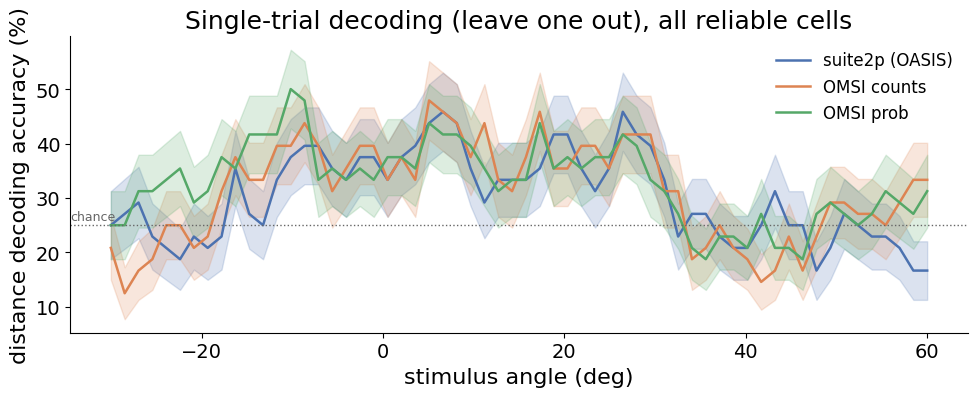

In [14]:
TrialDec = TrialDecoder()
single = {key: TrialDec.cross_validate(aggs[key], monocular=0, loo=True)
          for key in METHODS}
fig = plot_distance_compare(
    single, title='Single-trial decoding (leave one out), all reliable cells')

### Top cells only

Ranked by binocular `reliable_corr`. The original notebook indexed the full dataframe with
positions into the reliable subset, which mismatched the ranking against the neurons in `X`;
here the ranking is taken over `agg.cell_ids`, which is exactly the first axis of `X`.

Repeat 20/20
  Angle MAE:    1.59°
  Dist Acc:     26.7%
Repeat 20/20
  Angle MAE:    1.63°
  Dist Acc:     28.5%
Repeat 20/20
  Angle MAE:    1.61°
  Dist Acc:     32.3%


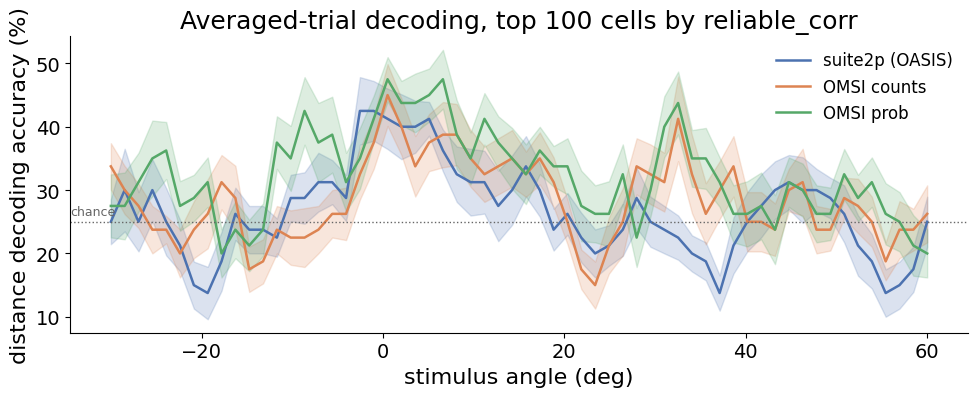

In [15]:
def top_cells(agg, field='reliable_corr', k=100):
    """Indices into X of the k cells scoring highest on a binocular field."""
    scores = cond_field(agg._df, field).loc[agg.cell_ids].astype(float).values
    order = np.argsort(np.nan_to_num(scores, nan=-np.inf))[::-1]
    return order[:k]


k_cells = 100
averaged_top = {key: AvgDec.cross_validate(aggs[key], monocular=0, n_repeats=20,
                                           cell_idx=top_cells(aggs[key], k=k_cells))
                for key in METHODS}
fig = plot_distance_compare(
    averaged_top, title=f'Averaged-trial decoding, top {k_cells} cells by reliable_corr')

## Per-cell response colormaps

One figure per method for the cells the methods disagree about, written under the suite2p
session's `results/spike-inference-compare/`. Set `SAVE_CELL_FIGURES = True` to run it; it writes
a few hundred PNGs and takes a while.

In [20]:
import time

SAVE_CELL_FIGURES = True

def save_figure(fig, path, attempts=3, pause=0.5):
    """Save with a retry so one transient OSError does not kill the whole loop."""
    for attempt in range(1, attempts + 1):
        try:
            fig.savefig(path, bbox_inches='tight', dpi=150)
            return True
        except OSError as exc:
            print(f'  [{exc.errno}] attempt {attempt} failed for {os.path.basename(path)}')
            if attempt == attempts:
                return False
            time.sleep(pause)


if SAVE_CELL_FIGURES:
    results_dir = os.path.join(base_data_dir,
                               f'{record_date}_{mouse_name}_{METHODS["suite2p"]}', 'results')
    compare_dir = create_new_result_dir(results_dir, 'spike-inference-compare')

    s2p_bino = modulated_ids('suite2p', 'binocular')
    omsi_bino = modulated_ids('omsi', 'binocular')
    groups = {
        'both':      s2p_bino & omsi_bino,
        'only_s2p':  s2p_bino - omsi_bino,
        'only_omsi': omsi_bino - s2p_bino,
    }
    group_dirs = {g: create_new_result_dir(compare_dir, g) for g in groups}
    cell_viz = {key: CellVisualizer(devices[key]) for key in METHODS}

    written = skipped = failed = 0
    for group, cell_ids in groups.items():
        print(f'{group}: {len(cell_ids)} cells')
        for cell_id in sorted(cell_ids):
            for key in METHODS:
                path = os.path.join(group_dirs[group], f'cell_{cell_id}_{key}.png')
                if os.path.exists(path):
                    skipped += 1
                    continue
                fig = cell_viz[key].plot_all_traces_colormap_distances(cell_id)
                if save_figure(fig, path):
                    written += 1
                else:
                    failed += 1
                plt.close(fig)

    print(f'done: {written} written, {skipped} already present, {failed} failed')
else:
    print('SAVE_CELL_FIGURES is False -- set it to True to write the per-cell PNGs')


Directory spike-inference-compare already exists
Directory both already exists
Directory only_s2p already exists
Directory only_omsi already exists
both: 59 cells


c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, N

only_s2p: 75 cells


c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, N

only_omsi: 22 cells


c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, N

done: 404 written, 64 already present, 0 failed


In [21]:
# ---- cells reliable under suite2p but not under OMSI prob -------------------
REF, ALT = 'suite2p', 'omsi_prob'
CORR_THRESHOLD = 0.85

reliable = {k: set(viz[k].reliable_classes['reliable']['cell_id'].values) & valid_ids
            for k in (REF, ALT)}
lost_ids = reliable[REF] - reliable[ALT]
gained_ids = reliable[ALT] - reliable[REF]

print(f'reliable in {LABELS[REF]}: {len(reliable[REF])}')
print(f'reliable in {LABELS[ALT]}: {len(reliable[ALT])}')
print(f'lost by {LABELS[ALT]}:   {len(lost_ids)}')
print(f'gained by {LABELS[ALT]}: {len(gained_ids)}')


def reliability_parts(df):
    """The two tests filter_by_reliability applies, as pandas expressions.

    Written this way deliberately: `== True` and `>=` are both False on NaN,
    while bool(np.nan) is True, so hand-rolling the criterion misclassifies the
    cells whose reliability correlation came back NaN.
    """
    mono_ok = cond_field(df, 'reliable', 'monocular') == True      # noqa: E712
    bino_ok = cond_field(df, 'reliable', 'binocular') == True      # noqa: E712
    mono_r = cond_field(df, 'reliable_corr', 'monocular').astype(float)
    bino_r = cond_field(df, 'reliable_corr', 'binocular').astype(float)
    corr_ok = (mono_r >= CORR_THRESHOLD) | (bino_r >= CORR_THRESHOLD)
    best = pd.concat([mono_r, bino_r], axis=1).max(axis=1)         # skips NaN
    return mono_ok, bino_ok, corr_ok, best


parts = {k: reliability_parts(dfs[k]) for k in (REF, ALT)}
ids = sorted(lost_ids)

lost = pd.DataFrame(index=pd.Index(ids, name='cell_id'))
for key, tag in ((REF, 'ref'), (ALT, 'alt')):
    mono_ok, bino_ok, _, best = parts[key]
    lost[f'{tag}_mono_ok'] = mono_ok.loc[ids].values
    lost[f'{tag}_bino_ok'] = bino_ok.loc[ids].values
    lost[f'{tag}_max_corr'] = best.loc[ids].round(3).values

alt_mono, alt_bino, alt_corr_ok, alt_best = parts[ALT]
reasons = []
for cell_id in ids:
    fails = []
    if not (alt_mono.loc[cell_id] and alt_bino.loc[cell_id]):
        fails.append('reliable flag')
    if not alt_corr_ok.loc[cell_id]:
        fails.append('corr is NaN' if np.isnan(alt_best.loc[cell_id])
                     else f'corr < {CORR_THRESHOLD}')
    reasons.append(' + '.join(fails))
lost['alt_failed_on'] = reasons

# Highest suite2p confidence first, so the sharpest disagreements come first.
lost = lost.sort_values('ref_max_corr', ascending=False)

print()
print(lost['alt_failed_on'].value_counts().to_string())
lost.head(20)


reliable in suite2p (OASIS): 684
reliable in OMSI prob: 511
lost by OMSI prob:   175
gained by OMSI prob: 2

alt_failed_on
corr < 0.85                    78
reliable flag                  57
reliable flag + corr < 0.85    40


,ref_mono_ok,ref_bino_ok,ref_max_corr,alt_mono_ok,alt_bino_ok,alt_max_corr,alt_failed_on
cell_id,,,,,,,
156,True,True,0.984,False,True,0.971,reliable flag
121,True,True,0.979,False,True,0.971,reliable flag
34,True,True,0.978,False,True,0.952,reliable flag
89,True,True,0.978,False,True,0.959,reliable flag
114,True,True,0.976,True,False,0.968,reliable flag
613,True,True,0.967,False,True,0.958,reliable flag
180,True,True,0.963,False,True,0.948,reliable flag
229,True,True,0.962,False,True,0.936,reliable flag
300,True,True,0.958,False,True,0.898,reliable flag


In [22]:
SAVE_DISAGREEMENT_FIGURES = True
N_CELLS = 40        # set to None for all of them

if SAVE_DISAGREEMENT_FIGURES:
    results_dir = os.path.join(base_data_dir,
                               f'{record_date}_{mouse_name}_{METHODS["suite2p"]}', 'results')
    compare_dir = create_new_result_dir(results_dir, 'spike-inference-compare')
    out_dir = create_new_result_dir(compare_dir, f'reliable_{REF}_not_{ALT}')

    disagree_viz = {key: CellVisualizer(devices[key]) for key in (REF, ALT)}
    targets = list(lost.index if N_CELLS is None else lost.index[:N_CELLS])

    written = skipped = failed = 0
    for cell_id in targets:
        for key in (REF, ALT):
            path = os.path.join(out_dir, f'cell_{cell_id}_{key}.png')
            if os.path.exists(path):
                skipped += 1
                continue
            fig = disagree_viz[key].plot_all_traces_colormap_distances(int(cell_id))
            if save_figure(fig, path):
                written += 1
            else:
                failed += 1
            plt.close(fig)

    print(f'{len(targets)} cells -> {written} written, {skipped} present, {failed} failed')
    print(out_dir)


Directory spike-inference-compare already exists
Creating directory: reliable_suite2p_not_omsi_prob


c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\scipy\stats\_axis_nan_policy.py:531: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\numpy\lib\_function_base_impl.py:2922: R

40 cells -> 80 written, 0 present, 0 failed
D:\data-distance-coding-project\processed-data\260903_SAM044_distance-temporal\results\spike-inference-compare\reliable_suite2p_not_omsi_prob
